# 10. Calibration: DMRG among the other methods

**Goal.** Put a DMRG number for the two-dimensional Hubbard model next to the numbers of a dozen other methods, reproduce one published DMRG value, and see which error dominates and where DMRG wins or loses.

On the chain (notebooks 3 and 4) the exact answer was always at hand. On the 2D Hubbard model it is not, so a number is trusted when independent methods with independent errors agree. In 2015 the Simons Collaboration on the Many-Electron Problem did exactly this comparison [LeBlanc et al., [arXiv:1505.02290](https://arxiv.org/abs/1505.02290)] and published every method's data alongside the paper. We use those files.

The model, in their convention (and TeNPy's): $H = -t\sum_{\langle ij\rangle\sigma}(c^\dagger_{i\sigma}c_{j\sigma} + \text{h.c.}) + U\sum_i n_{i\uparrow}n_{i\downarrow}$ on the square lattice, $t = 1$, energies per site.

In [1]:
import json
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from tenpy.algorithms import dmrg as tdmrg
from tenpy.models.hubbard import FermiHubbardModel
from tenpy.networks.mps import MPS

warnings.filterwarnings("ignore")  # TeNPy's notes about canonical form
RESULTS = Path("..") / "results"

## 1. The benchmark: one energy, many methods

Ground-state energy per site of the half-filled model in the thermodynamic limit, copied from the ancillary data of LeBlanc et al. (directory `t1_tprime0/t1_tprime0_U{4,8}_n1_T0`, files `E_<method>`; the last column is the error bar). Coupled cluster (UCCSD) and the multi-reference projected Hartree–Fock (MRPHF) are listed at their largest lattice, as in the paper.

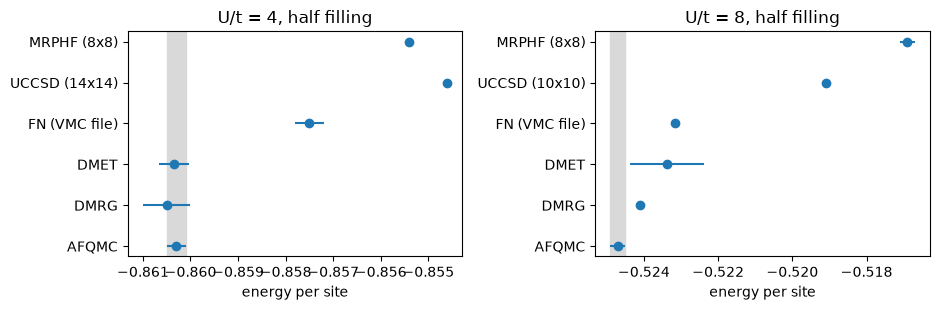

In [2]:
# (energy per site, error); from arXiv:1505.02290, ancillary files t1_tprime0_U*_n1_T0/E_*
benchmark = {
    4.0: {
        "AFQMC": (-0.8603, 0.0002),
        "DMRG": (-0.8605, 0.0005),
        "DMET": (-0.86035, 0.00032),
        "FN (VMC file)": (-0.8575, 0.0003),
        "UCCSD (14x14)": (-0.8546, 0.0),
        "MRPHF (8x8)": (-0.8554, 0.0),
    },
    8.0: {
        "AFQMC": (-0.5247, 0.0002),
        "DMRG": (-0.5241, 0.0001),
        "DMET": (-0.52337, 0.0010),
        "FN (VMC file)": (-0.52315, 0.00005),
        "UCCSD (10x10)": (-0.5191, 0.0),
        "MRPHF (8x8)": (-0.5169, 0.0002),
    },
}

fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.2))
for a, (U, rows) in zip(ax, benchmark.items(), strict=True):
    names = list(rows)
    E = np.array([rows[n][0] for n in names])
    dE = np.array([rows[n][1] for n in names])
    a.errorbar(E, range(len(names)), xerr=dE, fmt="o")
    a.axvspan(rows["AFQMC"][0] - rows["AFQMC"][1], rows["AFQMC"][0] + rows["AFQMC"][1], color="0.85")
    a.set_yticks(range(len(names)), names)
    a.set(xlabel="energy per site", title=f"U/t = {U:g}, half filling")
fig.tight_layout()

At half filling the spread between methods is about $5\times10^{-3}$, and three methods agree to a few $10^{-4}$. One of them is special: at half filling the particle-hole symmetry removes the Monte Carlo sign problem, so auxiliary-field QMC (AFQMC) is exact up to statistical and finite-size errors, both under control [LeBlanc et al., Sec. on AFQMC]. That makes it the reference here, and DMRG is the one being calibrated.

## 2. DMRG on an infinite cylinder: the procedure, live

DMRG works on cylinders. TeNPy's iDMRG (notebook 4, in TeNPy's form in notebook 5) gives the energy per site of an *infinite* cylinder directly, so the length is not an issue; the width $W$ and the bond dimension are. Live, on a two-leg ladder (open around, a $W = 2$ strip), with $N$ and $S^z$ conserved:

In [3]:
def hubbard_idmrg(W, U, chis, phi_ext=None, bc_y="periodic"):
    p = {"lattice": "Square", "Lx": 2, "Ly": W, "bc_x": "periodic", "bc_y": bc_y, "bc_MPS": "infinite",
         "t": 1.0, "U": U}
    if phi_ext is not None:
        p["phi_ext"] = phi_ext  # a flux 2 pi phi_ext through the cylinder; 1/2 makes it antiperiodic
    model = FermiHubbardModel(p)
    init = ["up" if (k // W + k % W) % 2 == 0 else "down" for k in range(2 * W)]  # half filling, S^z = 0
    psi = MPS.from_product_state(model.lat.mps_sites(), init, bc="infinite")
    rows, t0 = [], time.time()
    for chi in chis:
        eng = tdmrg.TwoSiteDMRGEngine(psi, model, {"trunc_params": {"chi_max": chi, "svd_min": 1e-12},
                                                    "mixer": chi == chis[0], "max_sweeps": 30, "min_sweeps": 6,
                                                    "max_E_err": 1e-9, "max_trunc_err": 1.0})
        E, _ = eng.run()
        rows.append({"chi": chi, "energy": E, "trunc_err": eng.sweep_stats["max_trunc_err"][-1],
                     "seconds": time.time() - t0})
    return rows


def extrapolate(rows, n_fit=3):
    # E linear in the truncation error, on the n_fit largest chi; error bar 0.2 x the extrapolation distance
    eps = np.array([r["trunc_err"] for r in rows])[-n_fit:]
    E = np.array([r["energy"] for r in rows])[-n_fit:]
    b, a = np.polyfit(eps, E, 1)
    return a, 0.2 * abs(E[-1] - a)


live = hubbard_idmrg(2, 8.0, [32, 64], bc_y="open")
for r in live:
    print(f"chi = {r['chi']:3d}   E/site = {r['energy']:.6f}   truncation error {r['trunc_err']:.1e}"
          f"   {r['seconds']:.0f} s")
E_ext, dE_ext = extrapolate(live, n_fit=2)
print(f"extrapolated to zero truncation error: {E_ext:.5f} +- {dE_ext:.5f}")

final DMRG state not in canonical form up to norm_tol_final=1.00e-10: norm_err=8.87e-08, calling psi.canonical_form()


chi =  32   E/site = -0.424595   truncation error 1.9e-04   8 s
chi =  64   E/site = -0.425750   truncation error 1.9e-05   17 s
extrapolated to zero truncation error: -0.42587 +- 0.00002


Two points fix a line but cannot test it, which is why the full runs below use four. LeBlanc et al. extrapolate the same way: energy linear in the truncation error, with an error bar of 1/5 of the distance from the last point to the extrapolation, "justified by comparison to the accuracy of previous DMRG data".

## 3. The width-4 cylinder, checked against the published value

On a periodic cylinder the allowed momenta around it are $k_y = 2\pi n/W$; with a flux of half a flux quantum (antiperiodic boundary) they shift to $2\pi(n + \tfrac12)/W$. The two finite-width errors have opposite signs, so the published DMRG data average the two ("phase averaging"). The full runs, $\chi$ up to 768, $U = 4$ and $8$ (from `python scripts/make_results.py hubbard_width4`, TeNPy, about half an hour on 4 cores):

U = 4: periodic -0.87028, antiperiodic -0.85989, average -0.86508 +- 0.00032; published -0.86448
U = 8: periodic -0.52641, antiperiodic -0.53192, average -0.52917 +- 0.00009; published -0.52831


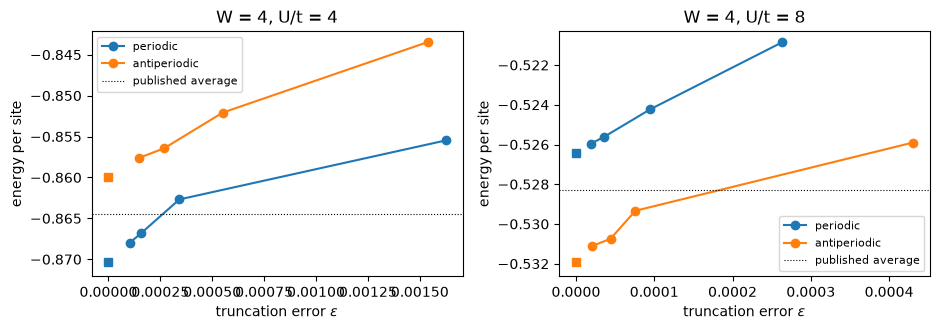

In [4]:
data = json.loads((RESULTS / "hubbard_width4.json").read_text())
published_w4 = {4.0: (-0.864483826696548, 2.5e-06), 8.0: (-0.52831022062594291, 1.4e-08)}  # E_DMRG_sizeinfx4

fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.4))
ours = {}
for a, U in zip(ax, (4.0, 8.0), strict=True):
    ext = {}
    for run in [r for r in data["runs"] if r["U"] == U]:
        eps = [r["trunc_err"] for r in run["runs"]]
        E = [r["energy"] for r in run["runs"]]
        ext[run["phi_ext"]] = extrapolate(run["runs"])
        lab = "periodic" if run["phi_ext"] == 0 else "antiperiodic"
        line, = a.plot(eps, E, "o-", label=lab)
        a.errorbar([0], [ext[run["phi_ext"]][0]], [ext[run["phi_ext"]][1]], fmt="s", color=line.get_color())
    avg = 0.5 * (ext[0.0][0] + ext[0.5][0])
    err = 0.5 * np.hypot(ext[0.0][1], ext[0.5][1])
    ours[U] = (avg, err)
    a.axhline(published_w4[U][0], color="k", lw=0.8, ls=":", label="published average")
    a.set(xlabel=r"truncation error $\varepsilon$", ylabel="energy per site", title=f"W = 4, U/t = {U:g}")
    a.legend(fontsize=8)
    print(f"U = {U:g}: periodic {ext[0.0][0]:.5f}, antiperiodic {ext[0.5][0]:.5f}, average {avg:.5f} +- {err:.5f};"
          f" published {published_w4[U][0]:.5f}")
fig.tight_layout()

The periodic and antiperiodic energies differ by $10^{-2}$ at $U = 4$ and half that at $U = 8$, with errors of opposite sign, which is why the average converges faster in $W$. At $U = 8$ the periodic energies are close to linear in $\varepsilon$; the antiperiodic ones still curve at $\chi = 768$. The phase-averaged result agrees with the published width-4 value to about $10^{-3}$ at both couplings, which is the remaining bond-dimension error of runs this small (the published ones quote $10^{-6}$ and below). Our 0.2-rule error bars are smaller than that gap: the rule assumes the runs are already in the linear regime, and the antiperiodic ones are not yet (exercise 1).

## 4. The width is the larger error

The published data contain the phase-averaged energy for several widths, in two orientations: the usual one, and cylinders rotated by 45° whose circumference is $\sqrt2$ times an integer. Following the paper, extrapolate in $1/W^3$, the finite-size form of the Heisenberg antiferromagnet:

U = 4: fit in 1/W^3 gives -0.8605 (published DMRG -0.8605); width-4 offset from AFQMC -0.0042
U = 8: fit in 1/W^3 gives -0.5241 (published DMRG -0.5241); width-4 offset from AFQMC -0.0036


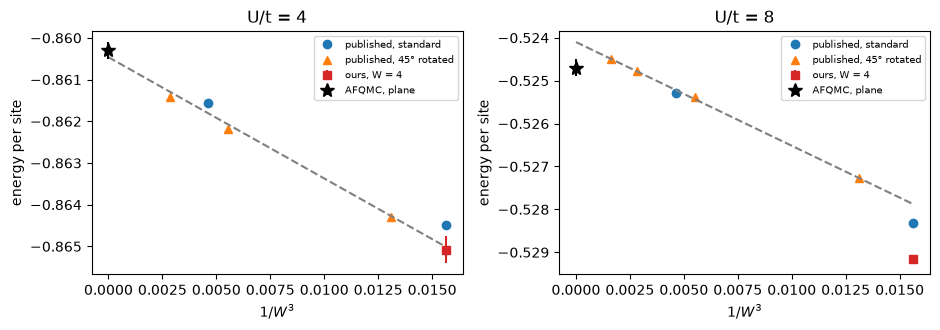

In [5]:
# E_DMRG_sizeinfx<W>: phase-averaged infinite-cylinder energies per site (arXiv:1505.02290 ancillary data)
widths = {
    4.0: {4: -0.864483826696548, 6: -0.86156064309651337, 3 * 2**0.5: -0.86428651770313136,
          4 * 2**0.5: -0.86217662874425738, 5 * 2**0.5: -0.86141254751671115},
    8.0: {4: -0.52831022062594291, 6: -0.52528584409402057, 3 * 2**0.5: -0.52727097449217597,
          4 * 2**0.5: -0.52537080453058849, 5 * 2**0.5: -0.5247646178923927, 6 * 2**0.5: -0.52450554021544127},
}

fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.4))
for a, U in zip(ax, (4.0, 8.0), strict=True):
    W = np.array(list(widths[U]))
    E = np.array(list(widths[U].values()))
    tilted = np.abs(W - np.round(W)) > 1e-9
    a.plot(W[~tilted] ** -3.0, E[~tilted], "o", label="published, standard")
    a.plot(W[tilted] ** -3.0, E[tilted], "^", label="published, 45° rotated")
    b, c = np.polyfit(W[W > 4.1] ** -3.0, E[W > 4.1], 1)
    x = np.linspace(0, 4**-3.0, 10)
    a.plot(x, b * x + c, "--", color="0.5")
    a.errorbar([4**-3.0], [ours[U][0]], [ours[U][1]], fmt="s", color="C3", label="ours, W = 4")
    a.errorbar([0], [benchmark[U]["AFQMC"][0]], [benchmark[U]["AFQMC"][1]], fmt="*", ms=10, color="k",
               label="AFQMC, plane")
    a.set(xlabel=r"$1/W^3$", ylabel="energy per site", title=f"U/t = {U:g}")
    a.legend(fontsize=7)
    print(f"U = {U:g}: fit in 1/W^3 gives {c:.4f} (published DMRG {benchmark[U]['DMRG'][0]:.4f});"
          f" width-4 offset from AFQMC {E[0] - benchmark[U]['AFQMC'][0]:+.4f}")
fig.tight_layout()

The $1/W^3$ fit lands on the published DMRG values for the plane. At width 4 the energy is about $4\times10^{-3}$ below the plane at both couplings: four times our own bond-dimension error, and a thousand times the error of the published width-4 runs. Getting $\chi$ right is the easy part; the finite circumference is what limits a 2D DMRG number, and every extra unit of width costs an exponential factor in $\chi$ (notebook 12). The widest cylinders in the benchmark are width 6 and $6\sqrt2 \approx 8.5$.

## 5. Where DMRG wins and where it loses

Half filling is the easy case for everybody: a charge gap (DMRG converges quickly) and no sign problem (QMC is exact). Doping removes both. Near $1/8$ doping, at $U/t = 8$ and density $n = 0.875$, the same benchmark finds (ancillary files `t1_tprime0_U8_n0.875_T0`):

In [6]:
doped = {  # energy per site at U = 8, n = 0.875; arXiv:1505.02290 ancillary data
    "AFQMC (constrained path)": (-0.766, 0.001),
    "DMRG": (-0.759, 0.004),
    "DMRG, width 4": (-0.763161134467, 0.00007),
    "DMRG, width 6": (-0.759419051149, 0.0009),
    "FN (VMC file)": (-0.749, 0.002),
    "UCCSD (16x12)": (-0.7123, 0.0),
}
for name, (E, dE) in doped.items():
    print(f"{name:26s} {E:.4f} +- {dE:.4f}")

AFQMC (constrained path)   -0.7660 +- 0.0010
DMRG                       -0.7590 +- 0.0040
DMRG, width 4              -0.7632 +- 0.0001
DMRG, width 6              -0.7594 +- 0.0009
FN (VMC file)              -0.7490 +- 0.0020
UCCSD (16x12)              -0.7123 +- 0.0000


The spread is now ten times larger, and nobody is exact: AFQMC needs a constraint to tame the sign problem, which brings a bias of its own (about half a percent against exact diagonalization on $4\times4$, as the paper reports), and DMRG finds stripes of holes wrapped around the cylinder, with metastable stripe fillings that have to be sorted out by hand (their DMRG section), on widths of only 4 and 6. Two years later many of the same authors combined DMRG, iPEPS, AFQMC and DMET to show that the ground state at $1/8$ doping and $U/t = 8$ is striped [Zheng et al., [arXiv:1701.00054](https://arxiv.org/abs/1701.00054); [Science 358, 1155 (2017)](https://doi.org/10.1126/science.aam7127)].

So, in short:

* **DMRG wins** where the sign problem makes QMC uncontrolled (doping, frustration, as in the J1-J2 model of notebooks 11–14), on quasi-one-dimensional systems, and whenever one wants a variational energy with a controlled error at fixed width. It also gives the wavefunction, so any correlation function comes for free.
* **DMRG loses** on width. The plane is reached only by extrapolation from widths 4 to about 8, and for gapless or metallic phases that extrapolation is the dominant and least controlled error. Where QMC has no sign problem, as at half filling here, QMC is the better tool.

## Summary

* A 2D DMRG number is trusted when it agrees with independent methods; the LeBlanc et al. benchmark publishes them all.
* Our TeNPy runs ($\chi \le 768$) reproduce the published width-4 energy to about $10^{-3}$, after extrapolating in the truncation error and averaging periodic and antiperiodic boundaries.
* The finite width (here $\sim4\times10^{-3}$ per site at $W = 4$) is far larger than the bond-dimension error, and only shrinks with wider, exponentially costlier cylinders.

## Exercises

1. In the width-4 data, extrapolate the antiperiodic runs with the two largest $\chi$ only, or with a quadratic fit. How much does the average move, and does it close the gap to the published value? Is the 0.2 rule a fair error bar?
2. In the live ladder run, add $\chi = 16$ and $48$ and fit all four points. Is $E(\varepsilon)$ linear? How much does the extrapolated energy move, and is the 0.2 rule a fair error bar?
3. Run `hubbard_idmrg(4, 8.0, [64, 128])` with and without `phi_ext=0.5`. Which boundary gives the lower energy, and why does the average converge faster in $W$ than either?
4. Use the benchmark's width data at $U = 4$ to fit $E(W) = E_\infty + b/W^2$ instead of $b/W^3$. How sensitive is $E_\infty$ to the assumed form?
5. At $U = 0$ the model is free. Compute the exact energy per site of the infinite width-4 cylinder by filling the negative single-particle energies $-2\cos k_x - 2\cos k_y$ with $k_y = 2\pi n/4$, and compare with `hubbard_idmrg(4, 0.0, [64, 128])`.